# Lesotho POI data: feature engineering for the GNN

**Input:** `processed_poi.csv` from `poi_eda.ipynb` (6,083 nodes, 19 raw node features, labels, spatial CV folds).
**Output:** `poi_engineered.csv`, the same nodes, with model-ready features for semi-supervised node classification.

"Ready for a GNN" here means:

1. **Every feature is numeric, finite and well-conditioned.** Heavy-tailed counts and distances are log-transformed,
   so no feature is dominated by a few town-centre or remote nodes.
2. **Features add what message passing cannot easily learn.** A GNN layer averages its neighbours' features. It
   cannot see density at several scales, the shape of a node's neighbourhood, its position in its town or
   sub-district, or its structural role in the graph unless those are given as inputs.
3. **No feature comes from the labels.** `name`, `tag_key`, `tag_value`, `subcategory` and `n_units` stay out
   (EDA Section 7), and nothing is computed from neighbours' categories. Label-based context (thematic edges,
   neighbour label shares) has to be computed inside each training fold in the model notebook.
4. **Nothing is fitted on the data here.** The transforms (logs, ratios, counts) have no fitted parameters, so the
   standard scaler is still fitted on the training folds in the model notebook, as the EDA decided.
5. **Feature columns are self-identifying.** Every model feature starts with a group prefix, so the model notebook
   can select a feature set with `df.filter(regex=...)`:

| Prefix | Group | Computed from |
|---|---|---|
| `loc_` | Location, density and town access | node positions only |
| `adm_` | Administrative context | positions + district / sub-district codes |
| `struct_` | Structural encodings of the k = 8 k-NN graph | positions only |
| `attr_` | Mapping attributes of the node | the node's own OSM attributes |
| `ctx_` | Mapping attributes of the surrounding area | neighbours' OSM attributes (not their labels) |

Identifier, label, graph and split columns are carried over unchanged, so edges are still built from `x_km`, `y_km`,
`adm1_idx` and `adm2_idx`. Only the POI data are used; no outside data are added.

In [1]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import sparse
from scipy.sparse.csgraph import connected_components
from scipy.spatial import ConvexHull, cKDTree

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)

IN_CSV = "processed_poi.csv"
OUT_CSV = "poi_engineered.csv"
K = 8                               # k-NN graph chosen in the EDA (smallest k that connects every node)
TOWN_MIN_POIS, TOWN_RADIUS_M = 50, 2000   # EDA town rule
SEED = 42

# Chart styling (same as poi_eda.ipynb)
SURFACE, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": "sans-serif", "font.sans-serif": ["Segoe UI", "DejaVu Sans"], "font.size": 9.5,
    "text.color": INK, "axes.labelcolor": INK2, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.edgecolor": AXIS, "axes.linewidth": 0.8, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.titlesize": 11, "axes.titleweight": "semibold", "axes.titlelocation": "left",
    "figure.dpi": 100, "legend.frameon": False,
})
print("numpy", np.__version__, "| pandas", pd.__version__)

numpy 2.4.6 | pandas 3.0.3


## 1. Input and column roles

The column roles follow the EDA data dictionary. Only the 19 `feature_loc` and `feature_attr` columns (plus
positions and administrative codes) are used to build features. Label columns are read so they can be carried over,
but no feature below uses them.

In [2]:
df = pd.read_csv(IN_CSV, keep_default_na=False, na_values=[""])

ID_COLS = ["node_id", "osm_id"]
INFO_COLS = ["osm_ids", "n_units", "name", "tag_key", "tag_value", "lon", "lat", "nearest_town"]
LABEL_COLS = ["category", "label", "is_labelled", "subcategory", "is_business"]
GRAPH_COLS = ["x_km", "y_km", "adm1_pcode", "adm1_name", "adm2_pcode", "adm2_name", "adm1_idx", "adm2_idx"]
SPLIT_COLS = ["fold", "block_id", "fold_boundary"]
RAW_LOC = ["x_km", "y_km", "dist_town_km", "dist_maseru_km", "is_urban", "density_500m", "density_2km",
           "density_10km", "nn1_dist_m", "knn8_mean_dist_m", "latrines_1km"]
RAW_ATTR = ["has_name", "has_address", "has_hours", "has_footprint", "log_footprint_m2", "is_point",
            "quality_score", "osm_id_rank"]

known = set(ID_COLS + INFO_COLS + LABEL_COLS + GRAPH_COLS + SPLIT_COLS + RAW_LOC + RAW_ATTR)
assert known == set(df.columns), set(df.columns) ^ known
assert df["node_id"].tolist() == list(range(len(df))), "node_id must be the row index"
assert df[RAW_LOC + RAW_ATTR + GRAPH_COLS + SPLIT_COLS].notna().all().all()

N = len(df)
XY = df[["x_km", "y_km"]].to_numpy() * 1000          # metres, UTM 35S
lab = df["is_labelled"].eq(1).to_numpy()
CATS = df.loc[lab].sort_values("label")["category"].unique().tolist()
print(f"{N:,} nodes x {df.shape[1]} columns | labelled {lab.sum():,} | unlabelled {(~lab).sum()} | "
      f"folds {sorted(df['fold'].unique().tolist())}")
print("Classes (label order):", CATS)
print(f"Raw features: {len(RAW_LOC)} location + {len(RAW_ATTR)} attribute")

6,083 nodes x 43 columns | labelled 5,952 | unlabelled 131 | folds [0, 1, 2, 3, 4]
Classes (label order): ['Infrastructure', 'Educational', 'Retail', 'Other', 'Food & Beverage', 'Tourism', 'Religious', 'Healthcare']
Raw features: 11 location + 8 attribute


## 2. Transforming the raw features

A GNN layer sums or averages neighbour features, so one extreme value spreads to every neighbour. The density and
distance features are heavily skewed (a town-centre node has 575 others within 2 km; the median node has 22). A
feature with skew above 1 gets `log1p`. The transform has no fitted parameters and keeps zeros at zero. Binary flags,
coordinates, `dist_maseru_km` (skew 0.3), `osm_id_rank` (uniform) and `log_footprint_m2` (already logged) are kept
as they are.

All engineered features go into one frame `F` through `add()`, which records each feature's group and description
for the data dictionary at the end.

In [3]:
F = pd.DataFrame(index=df.index)
FEATURES = {}   # name -> (group, description)
GROUPS = {"loc": "feature_loc", "adm": "feature_adm", "struct": "feature_struct", "attr": "feature_attr",
          "ctx": "feature_ctx"}

def add(name, values, desc):
    """Register one engineered feature; the prefix before '_' is its group."""
    assert name.split("_")[0] in GROUPS, name
    v = np.asarray(values, dtype=float)
    assert v.shape == (N,) and np.isfinite(v).all(), f"{name}: bad values"
    F[name] = v
    FEATURES[name] = (GROUPS[name.split("_")[0]], desc)

raw_stats = pd.DataFrame({"skew": df[RAW_LOC + RAW_ATTR].skew(), "zero_%": (df[RAW_LOC + RAW_ATTR] == 0).mean() * 100,
                          "max": df[RAW_LOC + RAW_ATTR].max()})
binary = [c for c in RAW_LOC + RAW_ATTR if set(df[c].unique()) <= {0, 1}]
to_log = [c for c in RAW_LOC + RAW_ATTR if c not in binary and raw_stats.loc[c, "skew"] > 1 and df[c].min() >= 0]
raw_stats["transform"] = ["binary" if c in binary else "log1p" if c in to_log else "none" for c in raw_stats.index]

RAW_NAMES = {  # raw column -> (engineered name, description)
    "x_km": ("loc_x_km", "UTM 35S easting, km"), "y_km": ("loc_y_km", "UTM 35S northing, km"),
    "dist_town_km": ("loc_log_dist_town_km", "log1p distance to the nearest data-derived town centre, km"),
    "dist_maseru_km": ("loc_dist_maseru_km", "Distance to the Maseru town centre, km"),
    "is_urban": ("loc_is_urban", f"1 if >= {TOWN_MIN_POIS} other nodes within {TOWN_RADIUS_M} m"),
    "density_500m": ("loc_log_density_500m", "log1p other nodes within 500 m"),
    "density_2km": ("loc_log_density_2km", "log1p other nodes within 2 km"),
    "density_10km": ("loc_log_density_10km", "log1p other nodes within 10 km"),
    "nn1_dist_m": ("loc_log_nn1_dist_m", "log1p distance to the nearest other node, m"),
    "knn8_mean_dist_m": ("loc_log_knn8_mean_dist_m", "log1p mean distance to the 8 nearest nodes, m"),
    "latrines_1km": ("loc_log_latrines_1km", "log1p household latrines within 1 km (mapping-biased to Mafeteng)"),
    "has_name": ("attr_has_name", "1 if named"), "has_address": ("attr_has_address", "1 if any address field"),
    "has_hours": ("attr_has_hours", "1 if opening hours are tagged"),
    "has_footprint": ("attr_has_footprint", "1 if mapped with a building outline"),
    "log_footprint_m2": ("attr_log_footprint_m2", "log1p largest outline area, m2; 0 without an outline"),
    "is_point": ("attr_is_point", "1 if mapped (also) as a point"),
    "quality_score": ("attr_quality_score", "Mean of has_name, has_address, has_hours, has_footprint"),
    "osm_id_rank": ("attr_osm_id_rank", "Percentile of the OSM id (proxy for mapping date); bias covariate"),
}
assert set(RAW_NAMES) == set(RAW_LOC + RAW_ATTR)
for c, (name, desc) in RAW_NAMES.items():
    name_ok = ("_log_" in name) == (c in to_log) or c == "log_footprint_m2"
    assert name_ok, f"{c}: name does not match its transform"
    add(name, np.log1p(df[c]) if c in to_log else df[c], desc)

raw_stats["skew_after"] = [F[RAW_NAMES[c][0]].skew() for c in raw_stats.index]
print(raw_stats.round(2).to_string())

                  skew  zero_%       max transform  skew_after
x_km              0.80    0.00    724.50      none        0.80
y_km             -0.59    0.00   6837.89      none       -0.59
dist_town_km      1.28    0.21     62.28     log1p        0.01
dist_maseru_km    0.30    0.02    176.58      none        0.30
is_urban          0.47   61.50      1.00    binary        0.47
density_500m      2.95   23.95    178.00     log1p        0.52
density_2km       2.19    8.35    575.00     log1p       -0.02
density_10km      1.11    0.02   1607.00     log1p        0.14
nn1_dist_m        3.21    0.03  11953.50     log1p        0.18
knn8_mean_dist_m  1.90    0.00  14603.20     log1p       -0.15
latrines_1km      5.53   63.31    251.00     log1p        1.76
has_name         -0.30   42.61      1.00    binary       -0.30
has_address       2.35   88.08      1.00    binary        2.35
has_hours         4.31   95.35      1.00    binary        4.31
has_footprint    -0.38   40.56      1.00    binary     

## 3. Density and spacing at more scales

The EDA found same-category dependence up to about 700 m, towns about 2 km across, and 10% of nodes more than 1.7 km
from any other POI. Three density radii (500 m, 2 km, 10 km) and two spacing measures do not cover that range well
at the small end (a market lane, a school compound) or the large end (a highland valley). Counts are added at 100 m,
250 m, 1 km, 5 km and 20 km, and distances to the 3rd, 16th and 32nd nearest node. The k-th distance is an
adaptive density (it is small in towns and large in the mountains), so it stays informative where fixed-radius
counts are zero. Recomputing the EDA's counts from the CSV positions checks that this notebook measures the same
thing (up to the 0.1 m rounding of the stored coordinates).

In [4]:
tree = cKDTree(XY)
KMAX = 32
dk, ik = tree.query(XY, k=KMAX + 2)

# Neighbour lists without the node itself (two nodes share a position, so self is not always in column 0)
not_self = ik != np.arange(N)[:, None]
assert (not_self.sum(1) == KMAX + 1).all()
nbr = ik[not_self].reshape(N, KMAX + 1)[:, :KMAX]          # 32 nearest other nodes, nearest first
nbr_d = dk[not_self].reshape(N, KMAX + 1)[:, :KMAX]

# The EDA's counts and spacing are reproduced from the same positions. The CSV rounds positions to 0.1 m, so a
# pair lying on a radius boundary can flip in or out: allow a difference of one neighbour on a few nodes.
for r, c in [(500, "density_500m"), (2000, "density_2km"), (10000, "density_10km")]:
    diff = tree.query_ball_point(XY, r, return_length=True) - 1 - df[c].to_numpy()
    assert np.abs(diff).max() <= 1 and (diff != 0).mean() < 0.005, c
    print(f"{c}: {(diff != 0).sum()} nodes differ by one neighbour (rounding)")
assert np.allclose(nbr_d[:, 0], df["nn1_dist_m"], atol=0.2)
assert np.allclose(nbr_d[:, :K].mean(1), df["knn8_mean_dist_m"], atol=0.2)
print("nn1 and knn8 spacing reproduced within 0.2 m")

for r in [100, 250, 1000, 5000, 20000]:
    label = f"{r}m" if r < 1000 else f"{r // 1000}km"
    add(f"loc_log_density_{label}", np.log1p(tree.query_ball_point(XY, r, return_length=True) - 1),
        f"log1p other nodes within {label.replace('km', ' km') if r >= 1000 else f'{r} m'}")
for k in [3, 16, 32]:
    add(f"loc_log_knn{k}_dist_m", np.log1p(nbr_d[:, k - 1]), f"log1p distance to the {k}th nearest node, m")

dens = [c for c in F if c.startswith("loc_log_density")]
dens = sorted(dens, key=lambda c: float(c.split("_")[-1].replace("km", "000").replace("m", "")))
print("\nMedian raw count by radius:", {c.split("_")[-1]: round(np.expm1(F[c]).median()) for c in dens})
print("Share of nodes with zero neighbours:", {c.split("_")[-1]: f"{(F[c] == 0).mean():.0%}" for c in dens})
print("Median k-th neighbour distance (m):",
      {k: round(float(np.median(nbr_d[:, k - 1]))) for k in [1, 3, 8, 16, 32]})

density_500m: 14 nodes differ by one neighbour (rounding)
density_2km: 16 nodes differ by one neighbour (rounding)


density_10km: 4 nodes differ by one neighbour (rounding)
nn1 and knn8 spacing reproduced within 0.2 m



Median raw count by radius: {'100m': 0, '250m': 1, '500m': 4, '1km': 9, '2km': 22, '5km': 71, '10km': 149, '20km': 357}
Share of nodes with zero neighbours: {'100m': '57%', '250m': '34%', '500m': '24%', '1km': '16%', '2km': '8%', '5km': '1%', '10km': '0%', '20km': '0%'}


Median k-th neighbour distance (m): {1: 121, 3: 372, 8: 839, 16: 1529, 32: 2628}


## 4. Shape of the neighbourhood

Counts say how many POIs are near a node, not how they are arranged. Arrangement separates types that have the same
density: shops line a main road, a school sits at the edge of a village, a clinic or church sits at its centre.
A mean-aggregating GNN layer sees neighbours as an unordered set, so it cannot recover this geometry on its own. Three
measures are taken over the 8 nearest nodes (the graph's own neighbourhood) and over the 32 nearest (the wider
settlement). All three are in [0, 1]:

- **Linearity**, `1 - λ2/λ1` from the covariance of neighbour positions: 1 when neighbours lie on a line (a road or
  valley), 0 when they are spread evenly.
- **Offset**, the distance from the node to its neighbours' centroid divided by their mean distance: 0 at the centre
  of a cluster, near 1 when all neighbours are on one side (edge of a settlement).
- **Angular gap**, the widest empty sector around the node as a share of 360°: large at edges and road ends.

In [5]:
def neighbourhood_shape(k):
    off = XY[nbr[:, :k]] - XY[:, None, :]                      # (N, k, 2) offsets to the k nearest, metres
    dist = np.hypot(off[..., 0], off[..., 1])
    mean_dist = dist.mean(1)

    c = off - off.mean(1, keepdims=True)
    lam = np.linalg.eigvalsh(np.einsum("nki,nkj->nij", c, c) / k)   # ascending: lam[:, 0] <= lam[:, 1]
    linearity = np.where(lam[:, 1] > 0, 1 - lam[:, 0] / np.where(lam[:, 1] > 0, lam[:, 1], 1), 0.0)

    offset = np.where(mean_dist > 0, np.hypot(*off.mean(1).T) / np.where(mean_dist > 0, mean_dist, 1), 0.0)

    ang = np.sort(np.arctan2(off[..., 1], off[..., 0]), axis=1)
    gaps = np.c_[np.diff(ang, axis=1), 2 * np.pi - (ang[:, -1] - ang[:, 0])]
    gap = gaps.max(1) / (2 * np.pi)
    return linearity.clip(0, 1), offset.clip(0, 1), gap

for k in [K, KMAX]:
    lin, offs, gap = neighbourhood_shape(k)
    add(f"loc_shape_linearity_k{k}", lin, f"1 - lambda2/lambda1 of the {k} nearest nodes' positions (1 = on a line)")
    add(f"loc_shape_offset_k{k}", offs, f"Distance to the {k} nearest nodes' centroid / their mean distance "
                                        "(0 = centre, 1 = edge)")
    add(f"loc_shape_gap_k{k}", gap, f"Widest empty sector around the node among its {k} nearest, share of 360 deg")

shape_cols = [c for c in F if c.startswith("loc_shape")]
print(F[shape_cols].describe().T[["mean", "std", "min", "25%", "50%", "75%", "max"]].round(3).to_string())
print("\nNodes whose 8 neighbours all fall in a half-plane (gap > 0.5):",
      f"{(F['loc_shape_gap_k8'] > 0.5).mean():.0%}")

                          mean    std    min    25%    50%    75%    max
loc_shape_linearity_k8   0.696  0.214  0.023  0.555  0.732  0.873  1.000
loc_shape_offset_k8      0.537  0.238  0.002  0.352  0.539  0.720  0.998
loc_shape_gap_k8         0.463  0.151  0.175  0.349  0.438  0.547  0.972
loc_shape_linearity_k32  0.567  0.204  0.022  0.425  0.586  0.728  0.972
loc_shape_offset_k32     0.483  0.221  0.017  0.307  0.475  0.656  0.994
loc_shape_gap_k32        0.262  0.119  0.081  0.175  0.232  0.319  0.896

Nodes whose 8 neighbours all fall in a half-plane (gap > 0.5): 34%


## 5. Towns and access to them

`dist_town_km` treats all 13 data-derived towns alike, yet being 2 km from Maseru (1,407 urban nodes) is not the same
as being 2 km from a 60-node district town. The towns are rebuilt with the EDA rule (a node is urban if at least 50
other nodes lie within 2 km; urban nodes within 2 km of each other form one town, centred on its densest node) and
checked against `dist_town_km`. Four features are added:

- **Town size**: POIs within 5 km of the nearest town centre. The count of urban nodes is not used because it undersizes
  compact towns: Mokhotlong, a district town, has only 1 node that passes the 50-within-2-km rule but 81 POIs within
  5 km of it.
- **Relative distance**: distance to the nearest town centre divided by that town's radius (90th percentile distance
  of its urban nodes from the centre, at least 1 km), so "town centre", "suburb" and "outside" mean the same for large
  and small towns.
- **Distance to the second-nearest town**: nodes between two towns versus nodes on a dead-end.
- **Town access** at 5 km and 25 km, a gravity index: the sum over towns of `size × exp(-distance / β)`. It is high
  near a large town and stays above zero between towns, unlike a count within a fixed radius.

In [6]:
urban = df["is_urban"].eq(1).to_numpy()
assert (urban == (df["density_2km"] >= TOWN_MIN_POIS)).all()
uidx = np.flatnonzero(urban)
up = cKDTree(XY[uidx]).query_pairs(TOWN_RADIUS_M, output_type="ndarray")
_, comp = connected_components(sparse.coo_matrix((np.ones(len(up)), (up[:, 0], up[:, 1])),
                                                 shape=(len(uidx),) * 2), directed=False)

u = pd.DataFrame({"node": uidx, "comp": comp, "density_2km": df["density_2km"].to_numpy()[uidx],
                  "adm2_name": df["adm2_name"].to_numpy()[uidx]})
g = u.groupby("comp")
towns = pd.DataFrame({"name": g["adm2_name"].agg(lambda s: s.mode()[0]), "urban_nodes": g.size(),
                      "centre_node": u.loc[g["density_2km"].idxmax(), "node"].to_numpy()})
towns = towns.sort_values("urban_nodes", ascending=False, kind="stable")
u["town"] = u["comp"].map(pd.Series(np.arange(len(towns)), index=towns.index))
towns = towns.reset_index(drop=True)
TXY = XY[towns["centre_node"].to_numpy()]
u["d_centre_m"] = np.hypot(*(XY[u["node"]] - TXY[u["town"]]).T)
towns["p90_urban_km"] = (u.groupby("town")["d_centre_m"].quantile(0.9) / 1000).round(2)
towns["radius_km"] = towns["p90_urban_km"].clip(lower=TOWN_RADIUS_M / 2000)
towns["pois_5km"] = tree.query_ball_point(TXY, 5000, return_length=True) - 1

# Check against the EDA's town features
D_town = np.hypot(XY[:, None, 0] - TXY[None, :, 0], XY[:, None, 1] - TXY[None, :, 1])   # (N, towns), metres
order = np.argsort(D_town, axis=1)
i1, i2 = order[:, 0], order[:, 1]
d1, d2 = D_town[np.arange(N), i1], D_town[np.arange(N), i2]
assert np.allclose(d1 / 1000, df["dist_town_km"], atol=0.002)
assert np.allclose(D_town[:, 0] / 1000, df["dist_maseru_km"], atol=0.002)
assert (towns["name"].to_numpy()[i1] == df["nearest_town"].to_numpy()).all()
print(f"{len(towns)} towns rebuilt; dist_town_km, dist_maseru_km and nearest_town match the EDA\n")
print(towns[["name", "urban_nodes", "pois_5km", "p90_urban_km", "radius_km"]].to_string())

size = towns["pois_5km"].to_numpy()
add("loc_log_town_size", np.log1p(size[i1]), "log1p POIs within 5 km of the nearest town centre")
add("loc_log_town_rel_dist", np.log1p(d1 / 1000 / towns["radius_km"].to_numpy()[i1]),
    "log1p distance to the nearest town centre / that town's radius (90th pct of its urban nodes, >= 1 km)")
add("loc_log_dist_town2_km", np.log1p(d2 / 1000), "log1p distance to the second-nearest town centre, km")
for beta_km in [5, 25]:
    add(f"loc_log_town_access_{beta_km}km", np.log1p((size * np.exp(-D_town / (beta_km * 1000))).sum(1)),
        f"log1p gravity index: sum over towns of town size * exp(-distance / {beta_km} km)")

town_cols = ["loc_log_town_size", "loc_log_town_rel_dist", "loc_log_dist_town2_km", "loc_log_town_access_5km",
             "loc_log_town_access_25km"]
print("\n" + F[town_cols].describe().T[["mean", "std", "min", "50%", "max"]].round(3).to_string())
rel = np.expm1(F["loc_log_town_rel_dist"])
print(f"\nNodes inside their nearest town's radius: {(rel <= 1).mean():.0%} | within 3 radii: {(rel <= 3).mean():.0%}")

13 towns rebuilt; dist_town_km, dist_maseru_km and nearest_town match the EDA

                                  name  urban_nodes  pois_5km  p90_urban_km  radius_km
0             Maseru (Maseru District)         1407      1148          5.64       5.64
1                         Tayateyaneng          200       233          1.64       1.64
2                             Mafeteng          130       158          1.59       1.59
3                          Qacha's Nek          108       135          1.60       1.60
4                               Leribe          105       128          1.81       1.81
5                              Quthing           81       103          1.47       1.47
6                        Mohale's Hoek           78       105          1.66       1.66
7                          Thaba-Tseka           64        84          1.56       1.56
8   Butha-Buthe (Butha-Buthe District)           61       100          1.53       1.53
9                            Manonyane           53

## 6. Administrative context

The model notebook can link nodes that share a sub-district (administrative edges), but an edge does not tell a node
where it stands within its unit. These features do, using only positions and the district codes:

- size of the node's sub-district and district (nodes, log);
- share of the sub-district's nodes that are urban (a town sub-district versus a rural one);
- the node's 2 km density as a percentile within its sub-district (1 = the busiest spot in the unit, where a
  sub-district's clinic, police post and shops tend to be);
- distance to the sub-district's centre of activity (the mean position of its nodes);
- a one-hot district indicator (10 columns). The EDA found strong district differences in mapping (Mafeteng's latrine
  campaign, Maseru mapped later), and the 5 km spatial blocks leave every district in several folds, so district
  indicators can absorb those offsets without handing over test blocks.

In [7]:
a2, a1 = df["adm2_pcode"], df["adm1_pcode"]
add("adm_log_adm2_nodes", np.log1p(a2.map(a2.value_counts())), "log1p nodes in the node's sub-district")
add("adm_log_adm1_nodes", np.log1p(a1.map(a1.value_counts())), "log1p nodes in the node's district")
add("adm_adm2_urban_share", df.groupby("adm2_pcode")["is_urban"].transform("mean"),
    "Share of the sub-district's nodes that are urban")
add("adm_density_pct_in_adm2", df.groupby("adm2_pcode")["density_2km"].rank(pct=True),
    "Percentile of the node's 2 km density within its sub-district (1 = busiest)")
centre = pd.DataFrame(XY, columns=["x", "y"]).groupby(a2.to_numpy()).transform("mean").to_numpy()
add("adm_log_dist_adm2_centre_km", np.log1p(np.hypot(*(XY - centre).T) / 1000),
    "log1p distance to the mean position of the sub-district's nodes, km")

districts = df.drop_duplicates("adm1_pcode").set_index("adm1_pcode")["adm1_name"].sort_index()
for code, name in districts.items():
    add(f"adm_district_{code}", a1.eq(code), f"1 if in {name} district")

adm_cols = [c for c in F if c.startswith("adm_") and not c.startswith("adm_district_")]
print(F[adm_cols].describe().T[["mean", "std", "min", "50%", "max"]].round(3).to_string())
per_a2 = a2.value_counts()
print(f"\nSub-districts: {len(per_a2)} | nodes per sub-district: min {per_a2.min()}, median {per_a2.median():.0f}, "
      f"max {per_a2.max()}")
print("District one-hot columns:", {f"adm_district_{c}": n for c, n in districts.items()})
assert (F.filter(like="adm_district_").sum(axis=1) == 1).all()

# Every district must stay in the training folds of every CV split, or its indicator is untrainable there
dist_fold = pd.crosstab(df["adm1_name"], df["fold"])
print("\nNodes per district and fold:\n" + dist_fold.to_string())
train_share = 1 - dist_fold.div(dist_fold.sum(axis=1), axis=0)
print(f"With any one fold held out, every district keeps >= {train_share.min().min():.0%} of its nodes in training "
      f"(worst: {train_share.min(axis=1).idxmin()})")

                              mean    std    min    50%    max
adm_log_adm2_nodes           4.961  1.252  1.946  4.727  7.130
adm_log_adm1_nodes           6.668  0.755  5.724  6.650  7.624
adm_adm2_urban_share         0.385  0.422  0.000  0.023  0.949
adm_density_pct_in_adm2      0.506  0.285  0.001  0.507  1.000
adm_log_dist_adm2_centre_km  1.592  0.742  0.079  1.528  3.828

Sub-districts: 78 | nodes per sub-district: min 6, median 48, max 1248
District one-hot columns: {'adm_district_LSA': 'Maseru', 'adm_district_LSB': 'Butha-Buthe', 'adm_district_LSC': 'Leribe', 'adm_district_LSD': 'Berea', 'adm_district_LSE': 'Mafeteng', 'adm_district_LSF': "Mohale's Hoek", 'adm_district_LSG': 'Quthing', 'adm_district_LSH': "Qacha's Nek", 'adm_district_LSJ': 'Mokhotlong', 'adm_district_LSK': 'Thaba-Tseka'}

Nodes per district and fold:
fold             0    1    2    3    4
adm1_name                             
Berea           40  397   46  224   65
Butha-Buthe     32   69   72  113   34
Leribe   

## 7. Mapping context of the surrounding area

The EDA showed that how a POI was mapped (named or not, point or outline, when) differs by category, and also by
area: whole villages were traced as outlines in one campaign, and town centres were named by other mappers later. A
node's own attributes mix both effects. Summarising the same attributes over the 32 nearest nodes separates them:

- **Area profile**: the share of the 32 nearest nodes that are named, have an outline, were mapped as a point, or
  carry an address or hours; plus the mean and spread of their `osm_id_rank` (one mapping campaign versus many).
- **Node versus area**: the node's outline size minus the mean outline size around it (schools, churches and
  hospitals are larger than the houses and shops next to them), and the node's `osm_id_rank` minus the area's mean
  (a node added apart from its surroundings, for example in a facility import).

The 32-node scale is wider than the k = 8 graph edges, so this context reaches past what two rounds of message
passing collect. Only neighbours' attributes are used, never their labels.

In [8]:
KC = KMAX
nb = nbr[:, :KC]
share = lambda col: df[col].to_numpy()[nb].mean(1)

add(f"ctx_named_share_k{KC}", share("has_name"), f"Share of the {KC} nearest nodes that are named")
add(f"ctx_footprint_share_k{KC}", share("has_footprint"), f"Share of the {KC} nearest nodes with a building outline")
add(f"ctx_point_share_k{KC}", share("is_point"), f"Share of the {KC} nearest nodes mapped as a point")
add(f"ctx_address_share_k{KC}", share("has_address"), f"Share of the {KC} nearest nodes with an address")
add(f"ctx_hours_share_k{KC}", share("has_hours"), f"Share of the {KC} nearest nodes with opening hours")

rank_nb = df["osm_id_rank"].to_numpy()[nb]
add(f"ctx_osm_id_rank_mean_k{KC}", rank_nb.mean(1), f"Mean osm_id_rank of the {KC} nearest nodes (when the area was mapped)")
add(f"ctx_osm_id_rank_std_k{KC}", rank_nb.std(1), f"Std of osm_id_rank of the {KC} nearest nodes (one campaign vs many)")
add(f"ctx_osm_id_rank_vs_k{KC}", df["osm_id_rank"] - rank_nb.mean(1),
    f"Node osm_id_rank minus the mean of its {KC} nearest nodes")

# Outline size relative to the outlines around it; 0 when the node or all its neighbours lack an outline
fp, has_fp = df["log_footprint_m2"].to_numpy(), df["has_footprint"].to_numpy().astype(bool)
nb_fp, nb_has = fp[nb], has_fp[nb]
n_fp = nb_has.sum(1)
nb_fp_mean = np.where(n_fp > 0, (nb_fp * nb_has).sum(1) / np.maximum(n_fp, 1), 0.0)
add(f"ctx_footprint_vs_k{KC}", np.where(has_fp & (n_fp > 0), fp - nb_fp_mean, 0.0),
    f"Node log outline area minus the mean log outline area of outlined nodes among its {KC} nearest "
    "(0 if either is missing)")

ctx_cols = [c for c in F if c.startswith("ctx_")]
print(F[ctx_cols].describe().T[["mean", "std", "min", "50%", "max"]].round(3).to_string())
print(f"\nOutlined nodes with no outlined node among their {KC} nearest: {(has_fp & (n_fp == 0)).sum()}")

                           mean    std    min    50%    max
ctx_named_share_k32       0.566  0.206  0.000  0.594  0.969
ctx_footprint_share_k32   0.589  0.196  0.000  0.594  1.000
ctx_point_share_k32       0.506  0.212  0.000  0.531  1.000
ctx_address_share_k32     0.139  0.193  0.000  0.062  0.938
ctx_hours_share_k32       0.051  0.100  0.000  0.000  0.625
ctx_osm_id_rank_mean_k32  0.497  0.117  0.104  0.501  0.823
ctx_osm_id_rank_std_k32   0.260  0.064  0.002  0.262  0.458
ctx_osm_id_rank_vs_k32    0.003  0.274 -0.679 -0.000  0.817
ctx_footprint_vs_k32      0.127  1.772 -7.699  0.000  8.163

Outlined nodes with no outlined node among their 32 nearest: 0


## 8. Structural encodings of the k-NN graph

Message-passing GNNs cannot count cycles or tell apart nodes whose neighbourhoods look alike at one hop but differ
further out, so structural encodings are a standard input. They are computed on the graph the EDA chose: k = 8 nearest
neighbours, made symmetric (an edge if either node lists the other), without self-loops.

- **In-degree**: how many nodes list this node among their 8 nearest. A node many others point to is a local hub
  (a central building in a village); a node nobody points to hangs off a cluster.
- **Reciprocity**: share of the node's 8 nearest that also list it.
- **Clustering coefficient**: share of the node's neighbour pairs that are linked themselves (a compact cluster
  versus a chain along a road).
- **Random-walk encoding (RWSE)**: the probability that a random walk from the node is back at the node after
  t = 2 to 16 steps, the diagonal of `P^t` with `P = D^-1 A`. It is the same for any ordering or sign convention,
  unlike Laplacian eigenvectors. With `S = D^-1/2 A D^-1/2 = U Λ Uᵀ` it equals `Σ_k U_ik² λ_k^t`, so one
  eigendecomposition gives every step exactly.

In [9]:
src = np.repeat(np.arange(N), K)
dst = nbr[:, :K].ravel()
A_dir = sparse.csr_matrix((np.ones(len(src)), (src, dst)), shape=(N, N))
A = ((A_dir + A_dir.T) > 0).astype(float).tocsr()
assert A.diagonal().sum() == 0 and connected_components(A, directed=False)[0] == 1
deg = np.asarray(A.sum(1)).ravel()
print(f"k={K} symmetric graph: {A.nnz // 2:,} undirected edges, one component, degree {deg.min():.0f}-{deg.max():.0f} "
      f"(median {np.median(deg):.0f})")

in_deg = np.asarray(A_dir.sum(0)).ravel()
mutual = np.asarray(A_dir.multiply(A_dir.T).sum(1)).ravel()
tri = np.asarray((A @ A).multiply(A).sum(1)).ravel() / 2
add(f"struct_knn{K}_in_degree", in_deg, f"Nodes that list this node among their {K} nearest (directed in-degree)")
add(f"struct_knn{K}_reciprocity", mutual / K, f"Share of the node's {K} nearest that also list it")
add(f"struct_knn{K}_clustering", 2 * tri / (deg * (deg - 1)), "Local clustering coefficient of the symmetric graph")

# RWSE from one eigendecomposition of the symmetric normalised adjacency
dinv = 1 / np.sqrt(deg)
S = (A.multiply(dinv[:, None]).multiply(dinv[None, :])).toarray()
lam, U = np.linalg.eigh(S)
U2 = U ** 2
RW_STEPS = list(range(2, 17))
rwse = np.stack([U2 @ lam ** t for t in RW_STEPS], axis=1).clip(0, 1)

# Check against explicit sparse powers of P = D^-1 A for the first steps
P = sparse.diags(1 / deg) @ A
Pt = P @ P
for t in [2, 3, 4]:
    assert np.allclose(Pt.diagonal(), rwse[:, t - 2], atol=1e-8), t
    Pt = Pt @ P
print("RWSE from the eigendecomposition matches explicit P^t for t = 2, 3, 4")

for j, t in enumerate(RW_STEPS):
    add(f"struct_rwse_{t:02d}", rwse[:, j], f"Random-walk return probability after {t} steps on the k={K} graph")

st_cols = [c for c in F if c.startswith("struct_")]
print(F[st_cols].describe().T[["mean", "std", "min", "50%", "max"]].round(4).to_string())
print(f"\nNodes no other node lists among its {K} nearest: {(in_deg == 0).mean():.1%}")

k=8 symmetric graph: 31,452 undirected edges, one component, degree 8-20 (median 10)


RWSE from the eigendecomposition matches explicit P^t for t = 2, 3, 4
                           mean     std     min     50%      max
struct_knn8_in_degree    8.0000  3.1757  0.0000  8.0000  19.0000
struct_knn8_reciprocity  0.7074  0.2691  0.0000  0.7500   1.0000
struct_knn8_clustering   0.6408  0.1409  0.1944  0.6374   1.0000
struct_rwse_02           0.0975  0.0096  0.0665  0.0978   0.1235
struct_rwse_03           0.0540  0.0123  0.0160  0.0534   0.0981
struct_rwse_04           0.0533  0.0112  0.0261  0.0521   0.0962
struct_rwse_05           0.0452  0.0121  0.0156  0.0440   0.0936
struct_rwse_06           0.0416  0.0117  0.0149  0.0402   0.0923
struct_rwse_07           0.0380  0.0116  0.0124  0.0366   0.0906
struct_rwse_08           0.0353  0.0114  0.0113  0.0339   0.0892
struct_rwse_09           0.0330  0.0111  0.0102  0.0314   0.0877
struct_rwse_10           0.0310  0.0108  0.0094  0.0295   0.0863
struct_rwse_11           0.0294  0.0106  0.0086  0.0278   0.0849
struct_rwse_12      

## 9. Redundancy check

Multi-scale features overlap: the 8th-neighbour distance and the 1 km count measure almost the same thing, and
consecutive random-walk steps are close. Near-duplicate inputs add parameters without adding information and make
feature attributions harder to read. The check uses only the features themselves, never the labels, so it cannot
leak test information. Features are visited in the order they were added (the EDA's own features first); a feature
is dropped if its Spearman |ρ| with an already kept feature is 0.95 or more. Constant features and features with a
single value on more than 99% of nodes are also dropped.

In [10]:
RHO_MAX, MODE_MAX = 0.95, 0.99
all_feats = list(F.columns)
mode_share = F.apply(lambda s: s.value_counts(normalize=True).iloc[0])
rho = F.rank().corr().abs()      # Spearman = Pearson on ranks

kept, dropped = [], []
for c in all_feats:
    if mode_share[c] > MODE_MAX:
        dropped.append((c, "near-constant", f"{mode_share[c]:.1%} one value"))
        continue
    partner = rho.loc[c, kept].idxmax() if kept else None
    if partner is not None and rho.loc[c, partner] >= RHO_MAX:
        dropped.append((c, partner, f"{rho.loc[c, partner]:.3f}"))
    else:
        kept.append(c)

drop_tbl = pd.DataFrame(dropped, columns=["dropped", "duplicates", "|rho|"])
print(f"{len(all_feats)} candidate features -> {len(kept)} kept, {len(dropped)} dropped\n")
print(drop_tbl.to_string(index=False))

grp = pd.Series({c: c.split("_")[0] for c in all_feats})
print("\nFeatures per group (candidates -> kept):",
      {g: f"{(grp == g).sum()} -> {grp[kept].eq(g).sum()}" for g in GROUPS})
max_rho = rho.loc[kept, kept].where(~np.eye(len(kept), dtype=bool)).max()
print(f"Largest |rho| between kept features: {max_rho.max():.3f} ({max_rho.idxmax()})")

80 candidate features -> 66 kept, 14 dropped

                 dropped               duplicates |rho|
     loc_log_knn3_dist_m loc_log_knn8_mean_dist_m 0.961
    loc_log_knn32_dist_m     loc_log_knn16_dist_m 0.968
loc_log_town_access_25km       loc_dist_maseru_km 0.964
          struct_rwse_04           struct_rwse_03 0.966
          struct_rwse_05           struct_rwse_03 0.951
          struct_rwse_07           struct_rwse_06 0.996
          struct_rwse_08           struct_rwse_06 0.986
          struct_rwse_09           struct_rwse_06 0.973
          struct_rwse_10           struct_rwse_06 0.957
          struct_rwse_12           struct_rwse_11 0.999
          struct_rwse_13           struct_rwse_11 0.996
          struct_rwse_14           struct_rwse_11 0.991
          struct_rwse_15           struct_rwse_11 0.985
          struct_rwse_16           struct_rwse_11 0.978

Features per group (candidates -> kept): {'loc': '30 -> 27', 'adm': '15 -> 15', 'struct': '18 -> 7', 'attr': '8 -

## 10. What the new features show

A quick visual check that each new family measures what it is meant to: one feature from four of the families,
mapped over all nodes (darker = higher; colour range clipped at the 2nd and 98th percentiles).

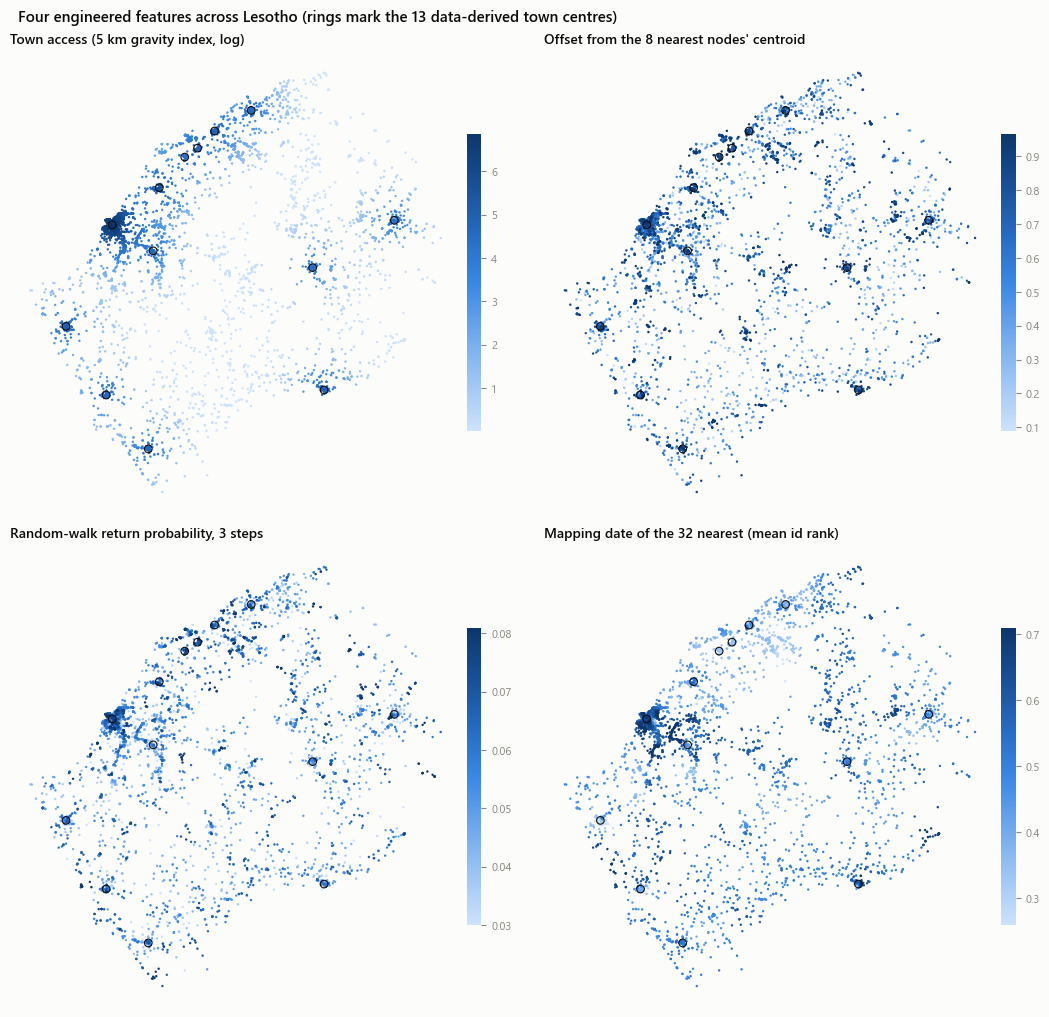

                          inside a town radius  outside
loc_log_town_access_5km                  6.108    2.174
loc_shape_offset_k8                      0.500    0.560
struct_rwse_03                           0.052    0.054
ctx_osm_id_rank_mean_k32                 0.518    0.493


In [11]:
from matplotlib.colors import LinearSegmentedColormap

SEQ = LinearSegmentedColormap.from_list("seq_blue", ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf",
                                                     "#184f95", "#0d366b"])
show = [("loc_log_town_access_5km", "Town access (5 km gravity index, log)"),
        ("loc_shape_offset_k8", "Offset from the 8 nearest nodes' centroid"),
        ("struct_rwse_03", "Random-walk return probability, 3 steps"),
        ("ctx_osm_id_rank_mean_k32", "Mapping date of the 32 nearest (mean id rank)")]

fig, axes = plt.subplots(2, 2, figsize=(11, 10.5))
for ax, (col, title) in zip(axes.ravel(), show):
    v = F[col].to_numpy()
    lo, hi = np.percentile(v, [2, 98])
    o = np.argsort(v)                                   # high values drawn on top
    sc = ax.scatter(df["x_km"].to_numpy()[o], df["y_km"].to_numpy()[o], c=v[o], s=3, lw=0, cmap=SEQ, vmin=lo, vmax=hi)
    ax.scatter(TXY[:, 0] / 1000, TXY[:, 1] / 1000, s=30, facecolors="none", edgecolors=INK, lw=.8)
    ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    for s in ax.spines.values():
        s.set_visible(False)
    ax.set_title(title, fontsize=10)
    cb = fig.colorbar(sc, ax=ax, shrink=.6, pad=.01)
    cb.outline.set_visible(False); cb.ax.tick_params(labelsize=8)
fig.suptitle("Four engineered features across Lesotho (rings mark the 13 data-derived town centres)", x=0.02,
             ha="left", fontsize=11, fontweight="semibold")
plt.tight_layout(); plt.show()

# Numbers behind the maps: medians inside towns versus outside
inside = np.expm1(F["loc_log_town_rel_dist"]) <= 1
print(pd.DataFrame({"inside a town radius": F.loc[inside, [c for c, _ in show]].median(),
                    "outside": F.loc[~inside, [c for c, _ in show]].median()}).round(3).to_string())

### Do the new features carry information about the category?

Mutual information between each kept feature and the 8-class label, on the labelled nodes. This is **descriptive
only**: it uses every fold's labels, so it is not used to choose features (the feature set above was fixed without
labels). It shows whether the engineered families add signal next to the EDA's 19 features.

New features in the top 25: 12 | in the top 10: 2

Mutual information by group (sum / best feature):
        features  total   best              best_feature
group                                                   
loc           27  3.893  0.249  loc_log_knn8_mean_dist_m
attr           8  1.492  0.461          attr_osm_id_rank
ctx            9  0.745  0.248      ctx_footprint_vs_k32
adm           15  0.705  0.213   adm_density_pct_in_adm2
struct         7  0.280  0.060            struct_rwse_02


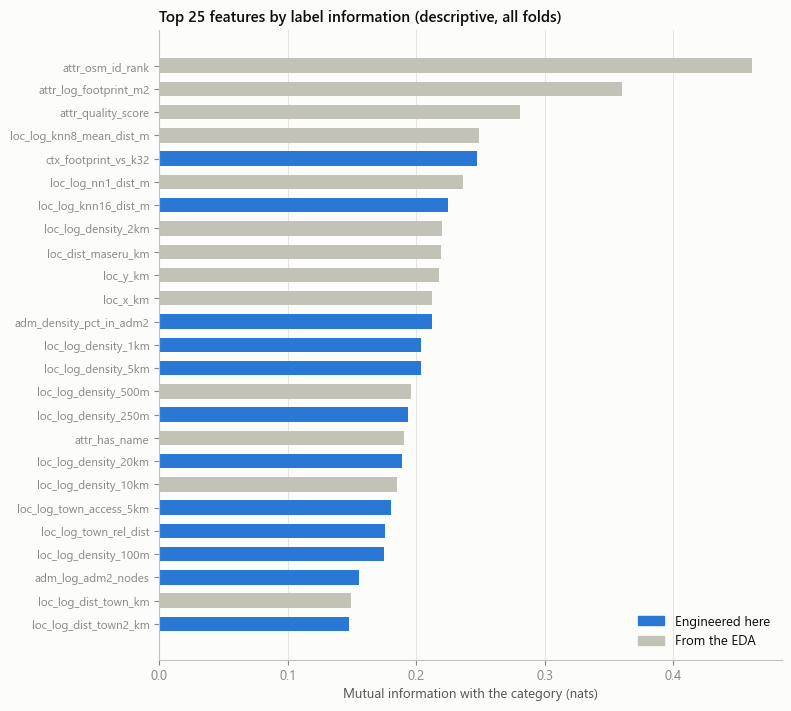

In [12]:
from sklearn.feature_selection import mutual_info_classif

eda_feats = {name for name, _ in RAW_NAMES.values()}
Xl, yl = F.loc[lab, kept], df.loc[lab, "label"].to_numpy()
is_binary = Xl.nunique().le(2).to_numpy()
mi = pd.Series(mutual_info_classif(Xl.to_numpy(), yl, discrete_features=is_binary, n_neighbors=5,
                                   random_state=SEED), index=kept).sort_values(ascending=False)
mi_tbl = pd.DataFrame({"mi": mi, "group": [c.split("_")[0] for c in mi.index],
                       "source": ["EDA" if c in eda_feats else "new" for c in mi.index]})

TOP = 25
top = mi_tbl.head(TOP)
print(f"New features in the top {TOP}: {top['source'].eq('new').sum()} | "
      f"in the top 10: {mi_tbl.head(10)['source'].eq('new').sum()}")
print("\nMutual information by group (sum / best feature):")
print(mi_tbl.groupby("group")["mi"].agg(features="size", total="sum", best="max")
      .assign(best_feature=mi_tbl.groupby("group")["mi"].idxmax()).round(3).sort_values("total", ascending=False)
      .to_string())

fig, ax = plt.subplots(figsize=(8, 7.2))
t = top.iloc[::-1]
colors = [BLUE if s == "new" else AXIS for s in t["source"]]
ax.barh(t.index, t["mi"], color=colors, height=.62)
ax.set_xlabel("Mutual information with the category (nats)")
ax.set_title(f"Top {TOP} features by label information (descriptive, all folds)")
ax.grid(axis="y", visible=False); ax.tick_params(axis="y", labelsize=8.5)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=BLUE, label="Engineered here"), Patch(color=AXIS, label="From the EDA")],
          loc="lower right")
plt.tight_layout(); plt.show()

**Findings.**

- **The new features add signal.** 12 of the 25 most informative features are engineered here. The strongest are
  the node's outline size relative to its surroundings (`ctx_footprint_vs_k32`, 0.25 nats, on par with the best
  location feature), the 16th-neighbour distance, and the node's density rank within its sub-district. The maps
  confirm that the families measure what they should: town access peaks at the 13 towns and fades between them,
  offset is high at the edges of villages, and the area's mapping date reproduces the EDA's pattern (Leribe and
  Butha-Buthe mapped early, Maseru late).
- **Structural encodings carry little label information on their own** (best 0.06 nats). They are kept because
  their value to a GNN comes from combining them with neighbour features in message passing, which a one-feature
  measure cannot show. The model notebook can test them as a group (`struct_`).
- **The mapping date is the most label-informative single feature** (`attr_osm_id_rank`, 0.46 nats). Types were
  mapped at different times: Religious nodes early (median id rank 0.20), Infrastructure late (median 0.66, a quarter
  above 0.87). That is OSM history, not a property of the place.
  It stays in the file, as the EDA decided, but a model that leans on it learns OSM history. The model notebook
  should report results with and without the three mapping-date features (column names containing `osm_id_rank`).

## 11. Export `poi_engineered.csv`

One row per node, in `node_id` order (the graph node index). Non-feature columns are carried over unchanged from
`processed_poi.csv`. Of the EDA's feature columns, only `x_km` and `y_km` are kept in raw form, because edges are
built from them; the rest appear only in their prefixed, transformed form. Feature values are rounded to
6 decimals. The data dictionary lists every column with its role.

In [13]:
CARRY = {  # carried-over column -> (role, description), from the EDA data dictionary
    "node_id": ("id", "Row index 0..N-1; use as the graph node index"),
    "osm_id": ("id", "OSM id of the representative feature"),
    "osm_ids": ("info", "All OSM ids merged into this node, ';'-separated"),
    "n_units": ("info", "Features merged into this node. Computed from labels: NOT a feature"),
    "name": ("info", "Name. Leaks the label: NOT a feature"),
    "tag_key": ("info", "OSM key the label came from: NOT a feature"),
    "tag_value": ("info", "OSM value the label came from: NOT a feature"),
    "lon": ("info", "Longitude, WGS84"), "lat": ("info", "Latitude, WGS84"),
    "nearest_town": ("info", "Sub-district name of the nearest data-derived town"),
    "category": ("label", "One of 8 categories, or Uncategorized"),
    "label": ("label", "Integer target 0-7; -1 = unlabelled (Uncategorized)"),
    "is_labelled": ("label", "1 if label >= 0"),
    "subcategory": ("label", "Finer type; possible secondary target"),
    "is_business": ("label", "1 for private-business subcategories"),
    "x_km": ("graph", "UTM 35S easting, km (for k-NN edges)"), "y_km": ("graph", "UTM 35S northing, km (for k-NN edges)"),
    "adm1_pcode": ("graph", "District code"), "adm1_name": ("graph", "District name"),
    "adm2_pcode": ("graph", "Sub-district code"), "adm2_name": ("graph", "Sub-district name"),
    "adm1_idx": ("graph", "District index 0-9 (administrative edges)"),
    "adm2_idx": ("graph", "Sub-district index 0-77 (administrative edges)"),
    "fold": ("split", "Spatial CV fold 0-4 (5 km blocks)"),
    "block_id": ("split", "5 km block the node falls in"),
    "fold_boundary": ("split", "1 if a node of another fold lies within 700 m (optional training buffer)"),
}
assert set(CARRY) == set(ID_COLS + INFO_COLS + LABEL_COLS + GRAPH_COLS + SPLIT_COLS)

FEATURE_COLS = sorted(kept, key=lambda c: list(GROUPS).index(c.split("_")[0]))   # stable: grouped by prefix
out = pd.concat([df[list(CARRY)], F[FEATURE_COLS].round(6)], axis=1)
out.to_csv(OUT_CSV, index=False, encoding="utf-8")

data_dictionary = pd.DataFrame(
    [(c, r, d) for c, (r, d) in CARRY.items()] + [(c, FEATURES[c][0], FEATURES[c][1]) for c in FEATURE_COLS],
    columns=["column", "role", "description"])
print(f"Wrote {OUT_CSV}: {out.shape[0]:,} rows x {out.shape[1]} columns "
      f"({len(CARRY)} carried over + {len(FEATURE_COLS)} features)\n")
print(data_dictionary["role"].value_counts().to_string(), "\n")
with pd.option_context("display.max_colwidth", 110):
    print(data_dictionary.to_string(index=False))

Wrote poi_engineered.csv: 6,083 rows x 92 columns (26 carried over + 66 features)

role
feature_loc       27
feature_adm       15
feature_ctx        9
info               8
graph              8
feature_attr       8
feature_struct     7
label              5
split              3
id                 2 

                     column           role                                                                                                           description
                    node_id             id                                                                         Row index 0..N-1; use as the graph node index
                     osm_id             id                                                                                  OSM id of the representative feature
                    osm_ids           info                                                                      All OSM ids merged into this node, ';'-separated
                    n_units           info              

## 12. Checking the file and that a GNN can use it

The file is read back and checked, then turned into a PyTorch Geometric graph the way the model notebook will do it,
for one CV split (fold 0 held out): the scaler is fitted on the training folds' rows only, the k = 8 edges are built
from `x_km`/`y_km`, and an untrained two-layer GraphSAGE runs one forward pass. Nothing is trained here.

In [14]:
warnings.filterwarnings("ignore", message="IProgress not found")   # tqdm notice from a PyG import
import torch
from torch_geometric.data import Data
from torch_geometric.nn import SAGEConv
from torch_geometric.utils import contains_isolated_nodes, contains_self_loops, is_undirected, to_undirected

chk = pd.read_csv(OUT_CSV, keep_default_na=False, na_values=[""])
FEAT_RE = r"^(loc|adm|struct|attr|ctx)_"
feat_cols = chk.filter(regex=FEAT_RE).columns.tolist()

# File checks
assert feat_cols == FEATURE_COLS and len(chk) == N
assert chk["node_id"].tolist() == list(range(N)) and chk["osm_id"].is_unique
assert np.isfinite(chk[feat_cols].to_numpy(float)).all()
assert np.allclose(chk[feat_cols].to_numpy(float), F[FEATURE_COLS].to_numpy(), atol=1e-6)
for c in CARRY:
    assert chk[c].equals(df[c]), c
LEAKY = {"name", "tag_key", "tag_value", "category", "label", "is_labelled", "subcategory", "is_business",
         "n_units", "osm_ids"}
assert not LEAKY & set(feat_cols)
print(f"File checks passed: {len(chk):,} nodes, {len(feat_cols)} features selected by regex {FEAT_RE!r}, "
      "carried-over columns identical to the input, no label-derived column among the features")

# One CV split, built as the model notebook will build it
TEST_FOLD = 0
train_rows = chk["fold"].ne(TEST_FOLD).to_numpy()
X = chk[feat_cols].to_numpy(np.float32)
mu, sd = X[train_rows].mean(0), X[train_rows].std(0)
assert (sd > 0).all(), "a feature is constant on the training folds"
Xs = (X - mu) / sd

xy = chk[["x_km", "y_km"]].to_numpy() * 1000
_, nn_i = cKDTree(xy).query(xy, k=K + 2)
nn_i = nn_i[nn_i != np.arange(N)[:, None]].reshape(N, K + 1)[:, :K]      # drop self explicitly
edge_index = to_undirected(torch.tensor(np.vstack([np.repeat(np.arange(N), K), nn_i.ravel()])), num_nodes=N)

y = torch.tensor(chk["label"].to_numpy())
labelled_t = torch.tensor(chk["is_labelled"].eq(1).to_numpy())
data = Data(x=torch.tensor(Xs), edge_index=edge_index, y=y,
            train_mask=torch.tensor(train_rows) & labelled_t, test_mask=torch.tensor(~train_rows) & labelled_t)
data.validate(raise_on_error=True)
assert is_undirected(edge_index) and not contains_self_loops(edge_index) and not contains_isolated_nodes(edge_index, N)
assert edge_index.size(1) // 2 == A.nnz // 2, "edges differ from the graph used for the structural encodings"
print(data)
print(f"Edges: {edge_index.size(1) // 2:,} undirected (same graph as Section 8) | train labelled "
      f"{int(data.train_mask.sum()):,} | test labelled {int(data.test_mask.sum()):,}")

torch.manual_seed(SEED)
conv1, conv2 = SAGEConv(data.num_features, 64), SAGEConv(64, len(CATS))
with torch.no_grad():
    logits = conv2(conv1(data.x, data.edge_index).relu(), data.edge_index)
assert logits.shape == (N, len(CATS)) and torch.isfinite(logits).all()
print(f"Untrained GraphSAGE forward pass: logits {tuple(logits.shape)}, all finite")

# How far the held-out fold sits from the training folds, in training standard deviations
shift = pd.Series(np.abs(Xs[~train_rows].mean(0)), index=feat_cols, dtype=float).sort_values(ascending=False)
print(f"\nFold {TEST_FOLD} feature shift (|mean| in training SDs): median {shift.median():.2f}, "
      f"{(shift > 0.5).sum()} features above 0.5 -> largest: {shift.head(5).round(2).to_dict()}")

File checks passed: 6,083 nodes, 66 features selected by regex '^(loc|adm|struct|attr|ctx)_', carried-over columns identical to the input, no label-derived column among the features
Data(x=[6083, 66], edge_index=[2, 62904], y=[6083], train_mask=[6083], test_mask=[6083])
Edges: 31,452 undirected (same graph as Section 8) | train labelled 4,770 | test labelled 1,182
Untrained GraphSAGE forward pass: logits (6083, 8), all finite

Fold 0 feature shift (|mean| in training SDs): median 0.13, 2 features above 0.5 -> largest: {'ctx_osm_id_rank_mean_k32': 0.55, 'adm_district_LSA': 0.52, 'adm_density_pct_in_adm2': 0.47, 'loc_log_latrines_1km': 0.43, 'ctx_point_share_k32': 0.41}


## 13. Summary

`poi_engineered.csv` holds the 6,083 nodes of `processed_poi.csv` with **66 model features** (80 engineered, 14
near-duplicates dropped without using labels) next to the unchanged id, label, graph and split columns.

| Group | Features | What it adds for the GNN |
|---|---|---|
| `loc_` | 27 | The EDA's location features, log-transformed; density at 8 radii (100 m to 20 km) and the 16th-neighbour distance; neighbourhood shape (linearity, offset, angular gap at k = 8 and 32); town size, position relative to the town's radius, second-nearest town, 5 km town-access index |
| `adm_` | 15 | Sub-district and district size, the sub-district's urban share, the node's density rank and distance to the centre within its sub-district; 10 district indicators |
| `struct_` | 7 | k = 8 graph in-degree, reciprocity, clustering; random-walk return probabilities at 2, 3, 6 and 11 steps |
| `attr_` | 8 | The EDA's mapping attributes of the node, unchanged |
| `ctx_` | 9 | Mapping profile of the 32 nearest nodes (named, outline, point, address, hours, mapping date and its spread); the node's outline size and mapping date relative to that area |

**Using the file in the model notebook**

- Features: `df.filter(regex=r"^(loc|adm|struct|attr|ctx)_")`. Fit the standard scaler on the training folds' rows
  of each split (the transforms here have no fitted parameters, so nothing leaks from the test fold).
- Edges: k = 8 nearest neighbours from `x_km`, `y_km`, made undirected, self excluded explicitly (two nodes share a
  position). Section 12 builds exactly the graph the `struct_` features were computed on. If k is tuned, the
  `struct_` features still describe the k = 8 graph; recompute them for the chosen k or keep them as fixed inputs.
  Administrative edges come from `adm2_idx` / `adm1_idx`.
- Labels: `label` (0-7, -1 unlabelled), evaluated with `fold` (5 km blocks) and optionally buffered with `fold_boundary`.
  Label-based context (neighbour label shares, thematic edges from co-location) must be computed inside each
  training fold; it is not in this file on purpose.

**Checks worth reporting with the model**

- **Mapping-date dependence.** `attr_osm_id_rank` is the single most label-informative feature because types were
  mapped at different times. Report results with and without the columns containing `osm_id_rank`.
- **Feature-group ablation.** `loc_` + `adm_` + `struct_` are computed from positions and codes only; `attr_` + `ctx_`
  describe how OSM volunteers mapped the area. Comparing the two sets shows how much of the accuracy is geography
  and how much is mapping style.
- **Spatial shift.** With fold 0 held out, the median feature is 0.13 training SDs off, but the area's mapping date
  and the Maseru indicator are off by about 0.5. Held-out blocks differ from the training blocks in mapping history,
  which a random split would hide; per-fold scores will show how much that costs.